# Experiment 4
## Electricity demand forecasting
### Real data

In [1]:
import sys, os
sys.path.append(os.path.abspath("..")) 
import importlib
import itertools
import src.ridge_signatures
importlib.reload(src.ridge_signatures)
import jax.numpy as jnp
from src.imports import * 
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_real
from src.utils import setup_latex_plotting, exponential_smoothing

All imports are fine


### Load data

In [2]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])
dates = df["DateTime"]

### Fit RidgeSig on data and calculate error metrics

In [12]:
from sklearn.metrics import mean_squared_error

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Set parameters and define dictionaries 
total_nb_days = df.size / 48
delay_days = 7
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
trunc_orders = [5]
lambdas = [ 0.001] #, 0.01, 0.1, 1, 10, 10**12] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2015-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
alpha1 = 0.005
#lams_efm = np.array([jnp.array([ 0.2, 0.03]), jnp.array([ 0.2, 0.03])])# np.linspace(16,20,10) #confiugure lambdas for EFMnp.log(2)/windows #
#lambda1_vals = np.logspace(-2, 0, 5)   # 0.01 → 1
#lambda2_vals = np.logspace(-2, 0, 5)
lambda1_vals = np.linspace(0.021, 0.022, 2) #Best rmse around 0.1 for trunc 5 
lambda2_vals = [10e-5]

lams_efm = np.array([
    jnp.array([l1, l2])
    for l1, l2 in itertools.product(lambda1_vals, lambda2_vals)
])
n_lams = lams_efm.shape[0]


METRICS = {
    "rmse": root_mean_squared_error,
    "mae": mean_absolute_error,
    "mape": mean_absolute_percentage_error,
}

models = {
    rf"$\overline{{T}}, {{\overline{{T}}}}^2": "baseline1",
    rf"$T, T^2, \overline{{T}}, {{\overline{{T}}}}^2$": "baseline2",
    rf"$\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$": "baseline3"
}

errors_sig_train = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}
errors_sig_test = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}

metrics = ("rmse", )#, "mae", "mape")

best_penalty = {}
model = {}
# Fit RidgeSig and calculate error metrics 
for j, d in enumerate(trunc_orders):
    for k, lam in enumerate(lams_efm):
        for m in metrics: 
            print(f'processing for {lam}')
            result_efm = ridge_signatures(
                covariates=temp,
                target=consumption / 10000,
                window=0, # not needed for EFM
                delay=delay,
                n_train=n_train,
                n_valid=n_train, #No val set
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=False,
                metric=m,
                signature_type='efm',
                T=total_nb_days,
                lam = lam, # EFM lambda is taken as constant
                max_window=max(windows), # window taken for the convergence of EFM 
                scale = True
            )
            errors_sig_train[d][m][k] = result_efm["error_train"]
            errors_sig_test[d][m][k] = result_efm["error_test"]
            best_penalty[(d,k,m)] = result_efm['best_penalty']
            model[k] = result_efm['model']

processing for [0.021  0.0001]
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 8.55 seconds
EFM signatures shape: (68352, 63)
processing for [0.022  0.0001]
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 8.40 seconds
EFM signatures shape: (68352, 63)


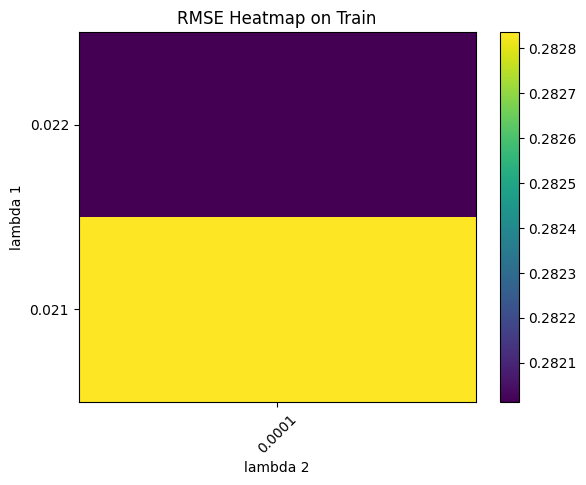

In [13]:
import numpy as np
import matplotlib.pyplot as plt

errors_flat = np.array(errors_sig_train[5]['rmse'])
errors_grid = errors_flat.reshape(len(lambda1_vals), len(lambda2_vals))

# Create heatmap
plt.figure()
plt.imshow(errors_grid, origin='lower', aspect='auto')

plt.xticks(range(len(lambda2_vals)), np.round(lambda2_vals, 4), rotation=45)
plt.yticks(range(len(lambda1_vals)), np.round(lambda1_vals, 4))

plt.xlabel("lambda 2")
plt.ylabel("lambda 1")
plt.title("RMSE Heatmap on Train")

plt.colorbar()
plt.show()


In [5]:
errors = []
for d in trunc_orders:
    row = {"model": f"Ridge regression (depth={d})"}
    row['rmse'] = errors_sig_train[d]['rmse'].min()
    errors.append(row)
print('train:', errors)
min_idx = np.argmin(np.array(errors_sig_train[5]['rmse'])) 
print(f"Best rmse with grid search lambda: {errors_sig_test[5]['rmse'][min_idx]} for lambda:{lams_efm[min_idx]}")

train: [{'model': 'Ridge regression (depth=5)', 'rmse': 0.2829469195332296}]
Best rmse with grid search lambda: 0.2905437809402158 for lambda:[0.022  0.0005]


In [6]:
print(f"Best rmse with grid search lambda: {errors_sig_test[5]['mae'][min_idx]} for lambda:{lams_efm[min_idx]}")

Best rmse with grid search lambda: 0.2042243519380747 for lambda:[0.022  0.0005]


In [7]:
print(f"Best rmse with grid search lambda: {errors_sig_test[5]['mape'][min_idx]} for lambda:{lams_efm[min_idx]}")

Best rmse with grid search lambda: 0.0378826406920515 for lambda:[0.022  0.0005]


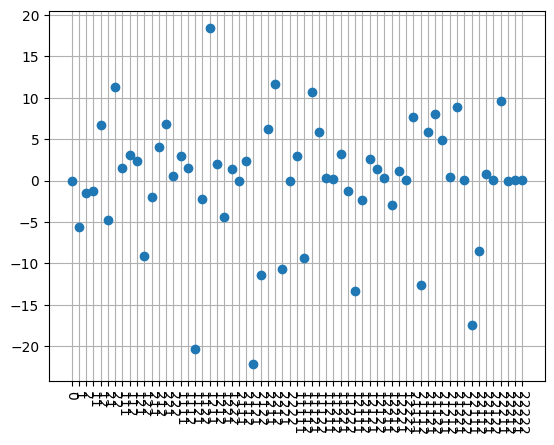

In [8]:
import signature.tensor_algebra as ta

coeff = ta.from_array(array=model[0].coef_, dim=2, trunc=5)
ta.plot_coefficients(coeff, trunc=5)